<a href="https://colab.research.google.com/github/adinuansah/time-to-attrition/blob/main/01_time_to_attrition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Who leaves, and when? Retention among HR professionals

**Methods:** Kaplan-Meier survival curves, log-rank tests, Cox proportional hazards model, time-split analysis
**Tools:** Python, pandas, lifelines, matplotlib, Google Colab

## Question

Which hiring and employment factors predict when employees leave, and when should retention efforts happen?

## Data

1,116 employees, mostly HR professionals across 16 industries, with 560 observed exits. Public dataset by Edward Babushkin, from [Kaggle](https://www.kaggle.com/datasets/aman2114/turnover-survival-analysis) (CC0 license).

Cleaning decisions:
- Removed 13 exact duplicate rows (identical on all 16 fields), treated as double-entered records.
- Tenure (`stag`) is in months: the maximum is 179, which is about 15 years.
- Fixed label errors (leading spaces, an encoding error) and grouped industries with fewer than 30 people into "Other".

## Key findings

1. **The risk window is months 6–24.** Retention is 94% at 6 months, 70% at 24 months, and 61% at 36. Half of those who leave are gone by about 51 months.
2. **Partly undeclared ("grey") pay is the strongest warning sign.** It carries 65% higher risk of leaving after controlling for other factors, concentrated in the first two years.
3. **Hires through friends and referrals stay longer, but only early on.** Their risk in the first 24 months is less than half the baseline, and the advantage disappears after year two.
4. **Employer-sourced hires become riskier over time:** about 50% higher risk after year two.
5. **Coaching type showed no measurable effect on retention.**

## Recommendations

1. Focus retention effort on months 6–24, not only onboarding.
2. Use referral hiring for early retention, and plan structured career conversations around months 18–24, when that advantage fades.
3. Add a retention check-in at 18–24 months for employer-sourced hires.
4. Don't expand coaching on retention grounds alone. Evaluate it with a proper comparison design first.

## Confidence and limitations

- These are associations, not proven causes. Grey pay may reflect wider employer instability.
- The sample is mostly HR professionals, so results may not generalize to other roles.
- With 32 factors tested, borderline results should be treated as signals to monitor.
- Two recruitment channel codes (`rabrecNErab`, `recNErab`) are not fully documented in the source.


In [13]:
# 1. Load data
import pandas as pd

# Source: Kaggle, aman2114/turnover-survival-analysis (CC0 license)
# Original data: Edward Babushkin
df = pd.read_csv('turnover.csv')

print(df.shape)
print(df['event'].value_counts())

(1129, 16)
event
1    571
0    558
Name: count, dtype: int64


In [14]:
# 2. Data inspection
print(df.dtypes)
print(df.isna().sum())
print(df.duplicated().sum())
print(df['stag'].describe())
df.head()

stag            float64
event             int64
gender           object
age             float64
industry         object
profession       object
traffic          object
coach            object
head_gender      object
greywage         object
way              object
extraversion    float64
independ        float64
selfcontrol     float64
anxiety         float64
novator         float64
dtype: object
stag            0
event           0
gender          0
age             0
industry        0
profession      0
traffic         0
coach           0
head_gender     0
greywage        0
way             0
extraversion    0
independ        0
selfcontrol     0
anxiety         0
novator         0
dtype: int64
13
count    1129.000000
mean       36.627526
std        34.096597
min         0.394251
25%        11.728953
50%        24.344969
75%        51.318275
max       179.449692
Name: stag, dtype: float64


,stag,event,gender,age,industry,profession,traffic,coach,head_gender,greywage,way,extraversion,independ,selfcontrol,anxiety,novator
0,7.030801,1,m,35.0,Banks,HR,rabrecNErab,no,f,white,bus,6.2,4.1,5.7,7.1,8.3
1,22.965092,1,m,33.0,Banks,HR,empjs,no,m,white,bus,6.2,4.1,5.7,7.1,8.3
2,15.934292,1,f,35.0,PowerGeneration,HR,rabrecNErab,no,m,white,bus,6.2,6.2,2.6,4.8,8.3
3,15.934292,1,f,35.0,PowerGeneration,HR,rabrecNErab,no,m,white,bus,5.4,7.6,4.9,2.5,6.7
4,8.410678,1,m,32.0,Retail,Commercial,youjs,yes,f,white,bus,3.0,4.1,8.0,7.1,3.7


In [15]:
# 3. Cleaning decisions
dupes = df[df.duplicated(keep=False)]
print(dupes.sort_values('stag').head(10))

df = df.drop_duplicates().reset_index(drop=True)
df['tenure_months'] = df['stag']
print(df.shape)   # expect (1116, 17)

           stag  event gender   age         industry profession      traffic  \
462    1.117043      1      f  54.0           Pharma         HR  rabrecNErab   
461    1.117043      1      f  54.0           Pharma         HR  rabrecNErab   
5      8.969199      1      f  42.0      manufacture         HR        empjs   
6      8.969199      1      f  42.0      manufacture         HR        empjs   
1124  10.611910      0      f  41.0            Banks         HR  rabrecNErab   
1125  10.611910      0      f  41.0            Banks         HR  rabrecNErab   
241   12.024641      1      m  30.0           Retail      Sales  rabrecNErab   
273   12.024641      1      m  30.0           Retail      Sales  rabrecNErab   
704   12.681725      1      f  36.0  PowerGeneration         HR        youjs   
766   12.681725      1      f  36.0  PowerGeneration         HR        youjs   

        coach head_gender greywage  way  extraversion  independ  selfcontrol  \
462        no           m    white  car

In [16]:
# 4. Category check
for col in ['gender','industry','profession','traffic','coach','head_gender','greywage','way']:
    print(df[col].value_counts(), '\n')

gender
f    841
m    275
Name: count, dtype: int64 

industry
Retail             283
manufacture        143
IT                 122
Banks              112
etc                 94
Consult             74
State               55
Building            41
transport           38
PowerGeneration     36
Telecom             36
Mining              24
Pharma              19
Agriculture         15
RealEstate          13
 HoReCa             11
Name: count, dtype: int64 

profession
HR                     745
IT                      74
Sales                   65
etc                     37
Marketing               31
BusinessDevelopment     27
Consult                 25
Commercial              23
manage                  22
Finanñe                 17
Engineer                15
Teaching                12
Accounting              10
Law                      7
PR                       6
Name: count, dtype: int64 

traffic
youjs          316
empjs          247
rabrecNErab    206
friends        116
referal       

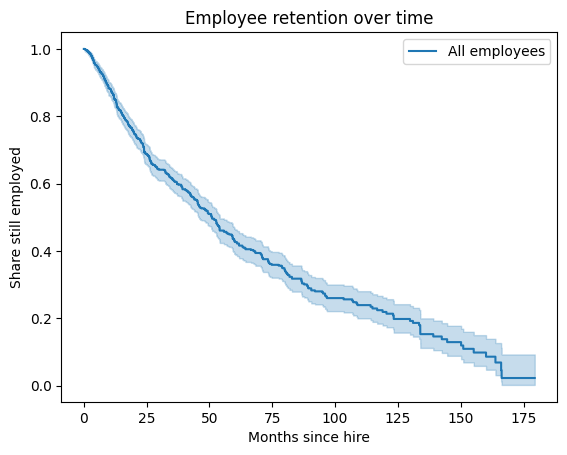

Median tenure before leaving: 50.98973306 months
6     0.940280
12    0.855983
24    0.696858
36    0.606897
Name: All employees, dtype: float64


In [17]:
# 5. Kaplan-Meier: overall retention
!pip install -q lifelines
from lifelines import KaplanMeierFitter
import matplotlib.pyplot as plt

kmf = KaplanMeierFitter()
kmf.fit(df['tenure_months'], event_observed=df['event'], label='All employees')

ax = kmf.plot_survival_function()
ax.set_xlabel('Months since hire')
ax.set_ylabel('Share still employed')
ax.set_title('Employee retention over time')
plt.show()

print('Median tenure before leaving:', kmf.median_survival_time_, 'months')
print(kmf.survival_function_at_times([6, 12, 24, 36]))

In [18]:
# 6. Clean category labels
df['industry'] = df['industry'].str.strip()
df['profession'] = df['profession'].replace({'Finanñe': 'Finance'})

def lump_rare(s, min_n=30, other='Other'):
    counts = s.value_counts()
    return s.where(s.map(counts) >= min_n, other)

df['industry_grp'] = lump_rare(df['industry'])
df['profession_grp'] = df['profession'].where(df['profession'] == 'HR', 'Non-HR')
df['coach_type'] = df['coach'].map({'no': 'No coach', 'my head': 'Manager coached', 'yes': 'Dedicated coach'})

print(df['industry_grp'].value_counts())

industry_grp
Retail             283
manufacture        143
IT                 122
Banks              112
etc                 94
Other               82
Consult             74
State               55
Building            41
transport           38
PowerGeneration     36
Telecom             36
Name: count, dtype: int64


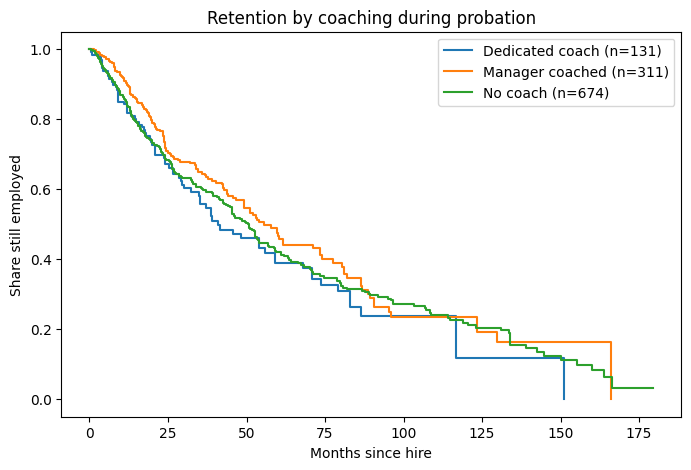

coach_type: log-rank p = 0.2334


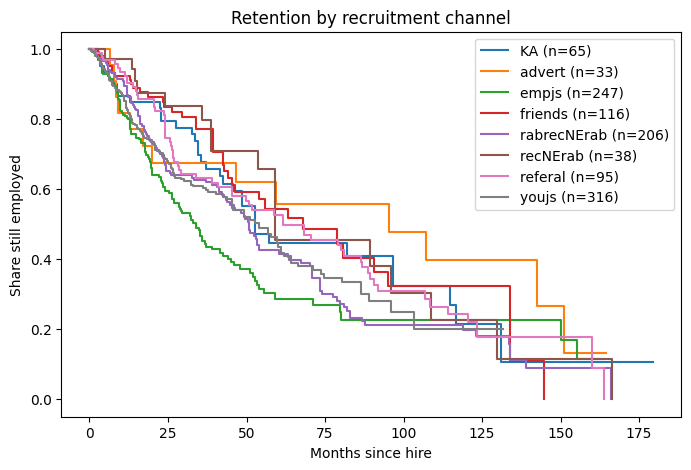

traffic: log-rank p = 0.0013


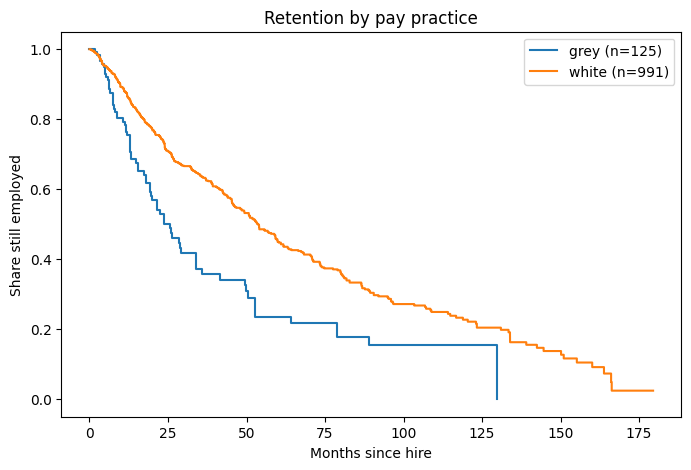

greywage: log-rank p = 0.0000


In [19]:
# 7. Kaplan-Meier by group, with log-rank test
from lifelines.statistics import multivariate_logrank_test

def km_by_group(col, title):
    fig, ax = plt.subplots(figsize=(8, 5))
    for grp, d in df.groupby(col):
        KaplanMeierFitter().fit(d['tenure_months'], d['event'], label=f'{grp} (n={len(d)})').plot_survival_function(ax=ax, ci_show=False)
    ax.set_xlabel('Months since hire'); ax.set_ylabel('Share still employed'); ax.set_title(title)
    plt.show()
    test = multivariate_logrank_test(df['tenure_months'], df[col], df['event'])
    print(f'{col}: log-rank p = {test.p_value:.4f}')

km_by_group('coach_type', 'Retention by coaching during probation')
km_by_group('traffic', 'Retention by recruitment channel')
km_by_group('greywage', 'Retention by pay practice')

<lifelines.CoxPHFitter: fitted with 1116 total observations, 556 right-censored observations>
             duration col = 'tenure_months'
                event col = 'event'
                penalizer = 0.01
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 1116
number of events observed = 560
   partial log-likelihood = -3327.06
         time fit was run = 2026-11-11 23:03:14 UTC

---
                              coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                     
age                           0.02      1.02      0.01            0.01            0.03                1.01                1.03
extraversion                  0.02      1.02      0.03           -0.04            0.09                0.96                1.09
independ                     -0.00      1.00      0.03           -0.07            0.07                0.94                1.07
selfcontrol                  -0.04      0.96      0.03           -0.10            0.03                0.90                1.03
anxiety                      -0.04      0.96      0.03           -0.11            0.02                0.90                1.02
novator                       0.00      1.00      0.03           -0.06            0.06                0.94                1.06
gender_m                     -0.13      0.88      0.12           -0.37            0.11                0.69                1.11
industry_grp_Banks            0.69      2.00      0.15            0.40            0.99                1.49                2.68
industry_grp_Building         0.81      2.26      0.21            0.41            1.22                1.51                3.39
industry_grp_Consult          0.63      1.87      0.18            0.27            0.98                1.32                2.66
industry_grp_IT              -0.29      0.75      0.19           -0.67            0.08                0.51                1.09
industry_grp_Other            0.25      1.28      0.18           -0.10            0.60                0.91                1.82
industry_grp_PowerGeneration  0.03      1.03      0.29           -0.54            0.60                0.58                1.82
industry_grp_State            0.39      1.47      0.20           -0.01            0.78                0.99                2.18
industry_grp_Telecom         -0.21      0.81      0.28           -0.76            0.34                0.47                1.41
industry_grp_etc              0.48      1.61      0.16            0.15            0.80                1.17                2.22
industry_grp_manufacture      0.24      1.27      0.15           -0.06            0.54                0.94                1.72
industry_grp_transport        0.20      1.22      0.27           -0.32            0.72                0.72                2.06
profession_grp_Non-HR         0.34      1.41      0.11            0.13            0.55                1.14                1.74
traffic_KA                   -0.41      0.67      0.20           -0.80           -0.02                0.45                0.98
traffic_advert               -0.54      0.58      0.30           -1.12            0.04                0.33                1.04
traffic_empjs                 0.27      1.32      0.12            0.03            0.52                1.03                1.68
traffic_friends              -0.48      0.62      0.18           -0.84           -0.13                0.43                0.88
traffic_rabrecNErab          -0.10      0.90      0.13           -0.35            0.15                0.70                1.16
traffic_recNErab             -0.56      0.57      0.26           -1.06           -0.06                0.35                0.95
traffic_referal              -0.29      0.75      0.16           -0.61            0.03                0.54                1.03
coach_type

Concordance: 0.651


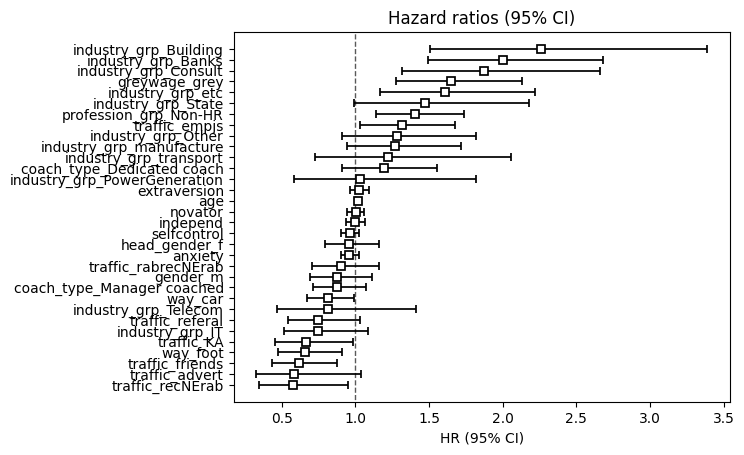

In [20]:
# 8. Cox proportional hazards model
from lifelines import CoxPHFitter

baselines = {'gender': 'f', 'industry_grp': 'Retail', 'profession_grp': 'HR',
             'traffic': 'youjs', 'coach_type': 'No coach', 'greywage': 'white',
             'way': 'bus', 'head_gender': 'm'}
num_cols = ['age', 'extraversion', 'independ', 'selfcontrol', 'anxiety', 'novator']

X = df[['tenure_months', 'event'] + num_cols].copy()
for col, base in baselines.items():
    d = pd.get_dummies(df[col], prefix=col, dtype=int)
    X = pd.concat([X, d.drop(columns=f'{col}_{base}')], axis=1)

cph = CoxPHFitter(penalizer=0.01)
cph.fit(X, duration_col='tenure_months', event_col='event')
cph.print_summary(decimals=2)
print('Concordance:', round(cph.concordance_index_, 3))

cph.plot(hazard_ratios=True)
plt.title('Hazard ratios (95% CI)')
plt.show()

In [21]:
# 9. Check proportional hazards assumption
cph.check_assumptions(X, p_value_threshold=0.05, show_plots=False)

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'selfcontrol' failed the non-proportional test: p-value is 0.0322.

   Advice 1: the functional form of the variable 'selfcontrol' might be incorrect. That is, there
may be non-linear terms missing. The proportional hazard test used is very sensitive to incorrect
functional forms. See documentation in link [D] below on how to specify a functional form.

   Advice 2: try binning the variable 'selfcontrol' using pd.cut, and then specify it in
`strata=['selfcontrol', ...]` in the call in `.fit`. See documentation in link [B] below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


2. Variable 'novator' failed the non-proportional test: p-value is 0.0231.

   Advice 1: the functional form of the variable 'novator' might be incorrect. That is, there may be
non-linear terms missing. The proportional hazard test used is very sensitive to incorrect
functional forms. See documentation in link [D] below on how to specify a 

[]

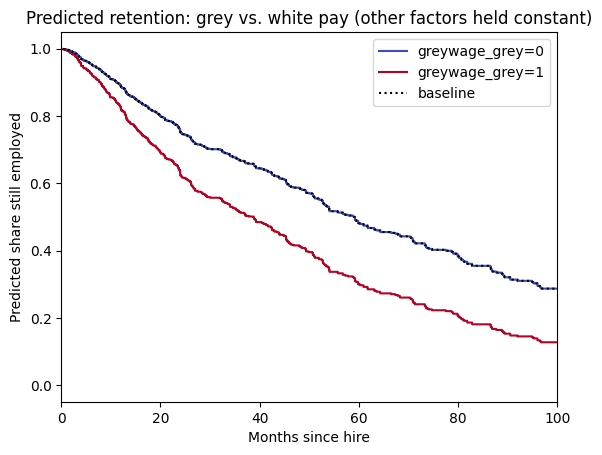

In [22]:
# 10. Executive chart: predicted retention, grey vs white pay
ax = cph.plot_partial_effects_on_outcome(covariates='greywage_grey', values=[0, 1], cmap='coolwarm')
ax.set_xlim(0, 100)
ax.set_xlabel('Months since hire'); ax.set_ylabel('Predicted share still employed')
ax.set_title('Predicted retention: grey vs. white pay (other factors held constant)')
plt.show()

In [23]:
# 11. Early vs late effects (split at 24 months)
early = X.copy()
early['event'] = ((X['tenure_months'] <= 24) & (X['event'] == 1)).astype(int)
early['tenure_months'] = X['tenure_months'].clip(upper=24)
cph_early = CoxPHFitter(penalizer=0.01).fit(early, 'tenure_months', 'event')

late = X[X['tenure_months'] > 24].copy()
late['entry'] = 24
cph_late = CoxPHFitter(penalizer=0.01).fit(late, 'tenure_months', 'event', entry_col='entry')

rows = ['greywage_grey', 'traffic_empjs', 'traffic_friends', 'traffic_referal', 'traffic_recNErab']
compare = pd.DataFrame({
    'HR months 0-24': cph_early.hazard_ratios_[rows],
    'HR after 24': cph_late.hazard_ratios_[rows],
    'p months 0-24': cph_early.summary.loc[rows, 'p'],
    'p after 24': cph_late.summary.loc[rows, 'p'],
}).round(3)
print(compare)
print('n still employed at 24 months:', len(late))

                  HR months 0-24  HR after 24  p months 0-24  p after 24
covariate                                                               
greywage_grey              1.763        1.441          0.000       0.118
traffic_empjs              1.282        1.503          0.109       0.050
traffic_friends            0.447        0.871          0.003       0.580
traffic_referal            0.604        1.031          0.035       0.894
traffic_recNErab           0.384        0.844          0.028       0.600
n still employed at 24 months: 569
